In [ ]:
%pip install cohere scikit-learn pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 303.0/303.0 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 66.0 MB/s eta 0:00:00
  Attempting uninstall: httpx-sse
    Found existing installation: httpx-sse 0.4.3
    Uninstalling httpx-sse-0.4.3:
      Successfully uninstalled httpx-sse-0.4.3


In [ ]:
import os
import cohere
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import time
import re

co = cohere.ClientV2(api_key=os.getenv("GOOGLE_API_KEY"))

# Definindo funções úteis na classificação

In [ ]:
def classificar_texto(texto, prompt_tamplate):
    prompt = prompt_tamplate
    for idx, txt in enumerate(texto, 1):
        prompt += f"{idx}. {txt}\n"
    prompt += (
        "\nResponda SOMENTE com 0 ou 1, um por linha, na mesma ordem dos textos fornecidos.\n"
        "Não explique, não justifique, não adicione nada além dos números."
    )

    res = co.chat(
        model="command-a-03-2025",
        messages=[
            {
                "content": prompt,
                "role": "user"
            }
        ],
    )

    resposta_texto = "".join([c.text for c in res.message.content if hasattr(c, "text")])

    return resposta_texto.strip(), resposta_texto.strip()

def parse_saida(saida, expected_len):
    matches = re.findall(r"\b[01]\b", saida)
    if len(matches) == expected_len:
        return matches
    else:
        return matches + [None] * (expected_len - len(matches))


def processar_lotes(df_final, prompt_template, prompt_name, batch_size=20, sleep_time=7):
    """
    Processa lotes de textos para classificação e atualiza o DataFrame com os resultados.
    """
    df_final = df_final
    df_final[prompt_name] = None
    df_final[f'{prompt_name}_raw'] = None

    print(f"classificação com: {prompt_name}")

    for i in range(0, len(df_final), batch_size):
        try:
            call_count = 0
            lote = df_final.iloc[i:i+batch_size]["text"].tolist()
            saida, raw_saida = classificar_texto(lote, prompt_template)

            resultados = parse_saida(saida, len(lote))
            raw_resultados = raw_saida.split("\n")

            for j, res in enumerate(resultados):
                idx = i + j
                if idx < len(df_final):
                    if res in ["0", "1"]:
                        df_final.at[idx, prompt_name] = int(res)
                    else:
                        df_final.at[idx, prompt_name] = None
                    df_final.at[idx, f'{prompt_name}_raw'] = (
                        raw_resultados[j] if j < len(raw_resultados) else None
                    )

            call_count += 1
            time.sleep(2)

            if call_count % 10 == 0:
                print("⏸️ Aguardando para respeitar limite de 10 chamadas/min...")
                time.sleep(sleep_time)

        except Exception as e:
            print(f"Erro no batch {i}–{i+batch_size} para {prompt_name}: {e}")
            time.sleep(15)

    return df_final

def plot_confusion(y_true, y_pred, titulo, path, output_dir):
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    plt.figure(figsize=(5,4))
    sns.heatmap(
                cm, 
                annot=True, 
                fmt="d", 
                cmap="Blues",
                xticklabels=["Não ódio (0)", "Ódio (1)"],
                yticklabels=["Não ódio (0)", "Ódio (1)"]
    )
    plt.xlabel("Predição")
    plt.ylabel("Real")
    plt.title(titulo)
    plt.tight_layout()
    plt.savefig(f"{output_dir}/confusion_matrix.png")
    plt.show()
    plt.close()

    report = classification_report(y_true, y_pred)
    with open(path, 'w', encoding='utf-8') as f:
        f.write(report)

    print("\nRelatório de Classificação:")
    print(report)

# Carregando dataset e prompts

In [ ]:
df = pd.read_csv("/content/hate_speech_classification_tcc/dados/Portuguese_Hate_Speech_Dataset/test.csv")
df['label'].value_counts(normalize=True)

,proportion
label,
0,0.7
1,0.3


In [8]:
zero_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/generativos/prompts/zero_shot/zero_shot.txt", "r").read()
one_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/generativos/prompts/one_shot/one_shot.txt", "r").read()
few_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/generativos/prompts/few_shot/few_shot.txt", "r").read()

# Classificação com: Zero Shot, One Shot e Few Shot

In [11]:
df_final = df.copy()

processar_lotes(df_final=df_final, prompt_template=zero_shot_prompt, prompt_name='pred_zero_shot')

df_final.to_csv("/content/hate_speech_classification_tcc/resultados/generativos/cohere/results_pred_cohere.csv", index=False)

classificação com: pred_zero_shot


In [20]:
processar_lotes(df_final=df_final, prompt_template=one_shot_prompt, prompt_name='pred_one_shot')

df_final.to_csv("/content/hate_speech_classification_tcc/resultados/generativos/cohere/results_pred_cohere.csv", index=False)

classificação com: pred_one_shot


In [13]:
processar_lotes(df_final=df_final, prompt_template=few_shot_prompt, prompt_name='pred_few_shot')
df_final.to_csv("/content/hate_speech_classification_tcc/resultados/generativos/cohere/results_pred_cohere.csv", index=False)

classificação com: pred_few_shot


In [14]:
df_final['pred_few_shot'].value_counts()

,count
pred_few_shot,
0,156
1,44


In [16]:
df_final['pred_few_shot'].isna().sum()

np.int64(0)

In [17]:
df_final.head()

,text,label,pred_zero_shot,pred_zero_shot_raw,pred_few_shot,pred_few_shot_raw
0,Sobre Filme #Disney beijo gay.,0,0,0,0,0
1,Acho vou pegar carona mimir,0,0,0,0,0
2,RT : #Abril. Seminário sobre Ideologia Gênero....,0,0,0,0,0
3,wtf tt sobre boatos fufas conhecidas Porto seg...,1,0,0,1,1
4,"Mulheres Rio, vamos aproximar meninas ciência?...",0,0,0,0,0


# Avaliação das técnicas de prompt

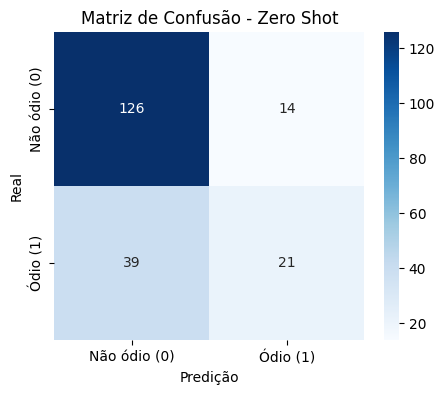


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.76      0.90      0.83       140
           1       0.60      0.35      0.44        60

    accuracy                           0.73       200
   macro avg       0.68      0.62      0.63       200
weighted avg       0.71      0.73      0.71       200



In [18]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/resultados/generativos/cohere/report_zero_shot.txt'
output_dir = '/content/hate_speech_classification_tcc/resultados/generativos/cohere/'
y_true = df_final["label"]
y_pred = df_final["pred_zero_shot"].astype(int)
plot_confusion(y_true, y_pred, "Matriz de Confusão - Zero Shot", path, output_dir)

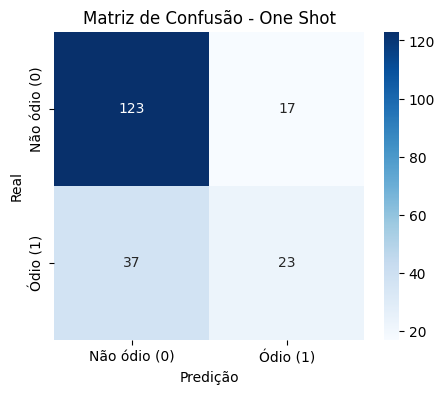


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.77      0.88      0.82       140
           1       0.57      0.38      0.46        60

    accuracy                           0.73       200
   macro avg       0.67      0.63      0.64       200
weighted avg       0.71      0.73      0.71       200



In [21]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/resultados/generativos/cohere/report_one_shot.txt'
output_dir = '/content/hate_speech_classification_tcc/resultados/generativos/cohere/'
y_true = df_final["label"]
y_pred = df_final["pred_one_shot"].astype(int)
plot_confusion(y_true, y_pred, "Matriz de Confusão - One Shot", path, output_dir)

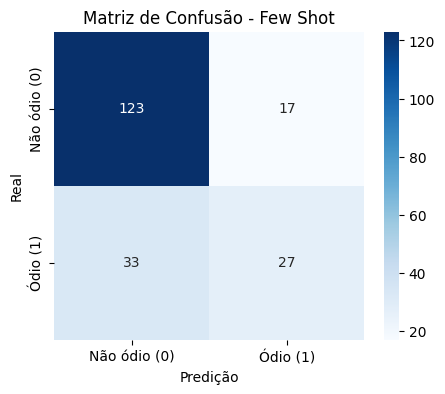


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.79      0.88      0.83       140
           1       0.61      0.45      0.52        60

    accuracy                           0.75       200
   macro avg       0.70      0.66      0.68       200
weighted avg       0.74      0.75      0.74       200



In [22]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/resultados/generativos/cohere/report_few_shot.txt'
output_dir = '/content/hate_speech_classification_tcc/resultados/generativos/cohere/'
y_true = df_final["label"]
y_pred = df_final["pred_few_shot"].astype(int)
plot_confusion(y_true, y_pred, "Matriz de Confusão - Few Shot", path, output_dir)